# Sales Data Analysis Project

## Project Overview

This project analyzes sales data to identify revenue trends, 
profitability, product category performance, and discount impact.

## Objectives

- Analyze total revenue and profit.
- Compare product category performance.
- Examine monthly sales trends.
- Evaluate the impact of discounts on profitability.

## Tools & Technologies

- Python
- SQL (SQLite)
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

## 1. Data Loading

In this section, we connect to the SQLite database and load the sales data for analysis.

In [2]:
# 1. Lazımi kitabxanaları import edirik

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# 2. SQLite database-ə qoşuluruq

conn = sqlite3.connect("noqte-satis-layihesi/shop.db")


# 3. Database-dəki cədvəlləri yoxlayırıq

tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print("Database tables:")
display(tables)


# 4. Məlumatları Pandas DataFrame-ə yükləyirik

orders = pd.read_sql_query(
    "SELECT * FROM orders",
    conn
)

order_items = pd.read_sql_query(
    "SELECT * FROM order_items",
    conn
)

products = pd.read_sql_query(
    "SELECT * FROM products",
    conn
)


# 5. Məlumatların ölçüsünü göstəririk

print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)


# 6. Hər cədvəldən ilk 5 sətri göstəririk

print("Orders Preview:")
display(orders.head())

print("Order Items Preview:")
display(order_items.head())

print("Products Preview:")
display(products.head())

Database tables:


,name
0,orders
1,products
2,order_items


Orders: (600, 4)
Order Items: (907, 7)
Products: (8, 5)
Orders Preview:


,order_id,order_date,customer_id,city
0,1,2025-11-24,29,Bakı
1,2,2025-02-17,56,Gəncə
2,3,2025-12-26,140,Digər
3,4,2025-03-23,179,Digər
4,5,2025-02-22,24,Digər


Order Items Preview:


,item_id,order_id,product_id,quantity,unit_price,unit_cost,discount
0,1,1,4,1,32.0,18.0,0.2
1,2,1,2,1,60.0,35.0,0.0
2,3,2,1,1,78.0,45.0,0.1
3,4,3,5,2,15.0,7.0,0.0
4,5,4,3,1,14.0,5.0,0.2


Products Preview:


,product_id,product_name,category,unit_cost,list_price
0,1,Qulaqlıq,Elektronika,45.0,78.0
1,2,Klaviatura,Elektronika,35.0,60.0
2,3,Telefon qabı,Aksesuar,5.0,14.0
3,4,Çanta,Aksesuar,18.0,32.0
4,5,Su qabı,Ev,7.0,15.0


## 2. Data Exploration

In this section, we explore the datasets, inspect their structure, and check for missing and duplicate values.

In [3]:
# 1. Dataset ölçüləri

print("Orders shape:", orders.shape)
print("Order Items shape:", order_items.shape)
print("Products shape:", products.shape)


# 2. Sütunlar və məlumat tipləri

print("\nOrders Information:")
orders.info()

print("\nOrder Items Information:")
order_items.info()

print("\nProducts Information:")
products.info()


# 3. Boş dəyərlərin yoxlanılması

print("\nMissing Values:")

print("Orders:")
display(orders.isnull().sum())

print("Order Items:")
display(order_items.isnull().sum())

print("Products:")
display(products.isnull().sum())


# 4. Təkrarlanan sətirlərin yoxlanılması

print("\nDuplicate Rows:")

print("Orders:", orders.duplicated().sum())
print("Order Items:", order_items.duplicated().sum())
print("Products:", products.duplicated().sum())

Orders shape: (600, 4)
Order Items shape: (907, 7)
Products shape: (8, 5)

Orders Information:
<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   order_id     600 non-null    int64
 1   order_date   600 non-null    str  
 2   customer_id  600 non-null    int64
 3   city         600 non-null    str  
dtypes: int64(2), str(2)
memory usage: 18.9 KB

Order Items Information:
<class 'pandas.DataFrame'>
RangeIndex: 907 entries, 0 to 906
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   item_id     907 non-null    int64  
 1   order_id    907 non-null    int64  
 2   product_id  907 non-null    int64  
 3   quantity    907 non-null    int64  
 4   unit_price  907 non-null    float64
 5   unit_cost   907 non-null    float64
 6   discount    907 non-null    float64
dtypes: float64(3), int64(4)
memory u

order_id       0
order_date     0
customer_id    0
city           0
dtype: int64

Order Items:


item_id       0
order_id      0
product_id    0
quantity      0
unit_price    0
unit_cost     0
discount      0
dtype: int64

Products:


product_id      0
product_name    0
category        0
unit_cost       0
list_price      0
dtype: int64


Duplicate Rows:
Orders: 0
Order Items: 0
Products: 0


### Data Quality Summary

- Total orders: 600
- Total order items: 907
- Total products: 8
- Missing values: 0
- Duplicate rows: 0

The datasets contain no missing values or duplicate rows.
The data is ready for further analysis.

## 3. SQL Analysis

In this section, we analyze sales data using SQL queries to identify revenue, profit, and sales trends.

In [4]:
query = """
SELECT
    p.product_name,
    p.category,
    SUM(oi.quantity) AS total_quantity,
    SUM(oi.quantity * oi.unit_price * (1 - oi.discount)) AS total_revenue,
    SUM(
        oi.quantity * oi.unit_price * (1 - oi.discount)
        - oi.quantity * oi.unit_cost
    ) AS total_profit

FROM order_items oi

JOIN products p
    ON oi.product_id = p.product_id

GROUP BY
    p.product_name,
    p.category

ORDER BY total_profit DESC;
"""

product_analysis = pd.read_sql_query(query, conn)

display(product_analysis)

,product_name,category,total_quantity,total_revenue,total_profit
0,Qulaqlıq,Elektronika,137,9383.4,3218.4
1,Klaviatura,Elektronika,123,6768.0,2463.0
2,Notbuk çantası,Aksesuar,152,6063.2,2415.2
3,Masa lampası,Ev,129,4633.2,1795.2
4,Siçan,Elektronika,158,4065.6,1695.6
5,Çanta,Aksesuar,141,4128.0,1590.0
6,Telefon qabı,Aksesuar,139,1790.6,1095.6
7,Su qabı,Ev,160,2182.5,1062.5


### Business Insights – Product Analysis

- Headphones generated the highest revenue and profit.
- Water Bottles had the highest sales volume.
- Phone Cases generated the lowest revenue.
- High sales volume does not always mean high profitability.

**Recommendation:** Focus on high-profit products while reviewing pricing and discount strategies for low-revenue products.

### 3.2 Category Performance Analysis

Analyze revenue and profit across different product categories.

In [5]:
query = """
SELECT
    p.category,

    SUM(oi.quantity) AS total_quantity,

    SUM(
        oi.quantity * oi.unit_price * (1 - oi.discount)
    ) AS total_revenue,

    SUM(
        oi.quantity * oi.unit_price * (1 - oi.discount)
        - oi.quantity * oi.unit_cost
    ) AS total_profit

FROM order_items oi

JOIN products p
    ON oi.product_id = p.product_id

GROUP BY p.category

ORDER BY total_revenue DESC;
"""

category_analysis = pd.read_sql_query(query, conn)

display(category_analysis)

,category,total_quantity,total_revenue,total_profit
0,Elektronika,418,20217.0,7377.0
1,Aksesuar,432,11981.8,5100.8
2,Ev,289,6815.7,2857.7


In [6]:
category_analysis["profit_margin"] = (
    category_analysis["total_profit"]
    / category_analysis["total_revenue"]
) * 100

category_analysis["profit_margin"] = (
    category_analysis["profit_margin"].round(2)
)

display(category_analysis)

,category,total_quantity,total_revenue,total_profit,profit_margin
0,Elektronika,418,20217.0,7377.0,36.49
1,Aksesuar,432,11981.8,5100.8,42.57
2,Ev,289,6815.7,2857.7,41.93


### Business Insights – Category Analysis

- Electronics generated the highest total revenue and profit.
- Accessories had the highest sales volume.
- Accessories achieved the highest profit margin (42.57%).
- Home category generated the lowest total revenue.

**Recommendation:** Maintain the strong revenue performance of Electronics and explore opportunities to expand the Accessories category due to its higher profit margin.

### 3.3 Monthly Sales Analysis

Analyze monthly revenue and profit trends throughout 2025.

In [7]:
category_analysis["profit_margin"] = (
    category_analysis["total_profit"]
    / category_analysis["total_revenue"]
) * 100

category_analysis["profit_margin"] = (
    category_analysis["profit_margin"].round(2)
)

display(category_analysis)

,category,total_quantity,total_revenue,total_profit,profit_margin
0,Elektronika,418,20217.0,7377.0,36.49
1,Aksesuar,432,11981.8,5100.8,42.57
2,Ev,289,6815.7,2857.7,41.93


Business Insights – Category Analysis
- Electronics generated the highest revenue (20,217 AZN) and total profit (7,377 AZN).
- Accessories had the highest sales volume (432 units).
- Accessories achieved the highest profit margin (42.57%).
- Home generated the lowest revenue (6,815.7 AZN) and profit (2,857.7 AZN).

### 3.3 Monthly Sales Analysis

Analyze monthly revenue and profit trends throughout 2025.

In [8]:
query = """
SELECT
    substr(o.order_date, 1, 7) AS month,

    SUM(
        oi.quantity * oi.unit_price * (1 - oi.discount)
    ) AS total_revenue,

    SUM(
        oi.quantity * oi.unit_price * (1 - oi.discount)
        - oi.quantity * oi.unit_cost
    ) AS total_profit

FROM orders o

JOIN order_items oi
    ON o.order_id = oi.order_id

GROUP BY substr(o.order_date, 1, 7)

ORDER BY month;
"""

monthly_analysis = pd.read_sql_query(query, conn)

display(monthly_analysis)

,month,total_revenue,total_profit
0,2025-01,2517.8,971.8
1,2025-02,3034.3,1139.3
2,2025-03,3303.8,1260.8
3,2025-04,2390.2,937.2
4,2025-05,2841.1,1096.1
5,2025-06,3711.4,1532.4
6,2025-07,3503.9,1383.9
7,2025-08,2960.2,1230.2
8,2025-09,3081.5,1131.5
9,2025-10,3812.6,1539.6


### Business Insights – Monthly Sales Analysis

- December generated the highest revenue (4,206 AZN) and profit (1,678 AZN).
- April had the lowest revenue (2,390.2 AZN) and profit (937.2 AZN).
- Revenue increased significantly from May to June.
- October and November also showed strong revenue performance.
- Monthly profit generally followed the same trend as revenue.

**Key Finding:** December was the strongest month in 2025, while April recorded the lowest sales performance.

### 3.4 Discount Analysis

Analyze how different discount rates affect sales volume, total profit, and profit per unit.

In [9]:
query = """
SELECT
    discount,

    SUM(quantity) AS total_quantity,

    SUM(
        quantity * unit_price * (1 - discount)
        - quantity * unit_cost
    ) AS total_profit,

    ROUND(
        SUM(
            quantity * unit_price * (1 - discount)
            - quantity * unit_cost
        ) * 1.0 / SUM(quantity),
        2
    ) AS profit_per_unit

FROM order_items

GROUP BY discount

ORDER BY discount;
"""

discount_analysis = pd.read_sql_query(query, conn)

display(discount_analysis)

,discount,total_quantity,total_profit,profit_per_unit
0,0.0,532,8582.0,16.13
1,0.1,281,3852.6,13.71
2,0.2,242,2412.4,9.97
3,0.3,84,488.5,5.82


### Business Insights – Discount Analysis

- Products without discounts generated the highest total profit (8,582 AZN).
- Profit per unit decreased as the discount rate increased.
- Products with a 30% discount had the lowest profit per unit (5.82 AZN).
- Sales volume was highest for products without discounts (532 units).
- Higher discounts were associated with lower profit per unit.

**Recommendation:** Review discount strategies carefully to maintain profitability. Higher discounts should be evaluated based on their ability to generate additional sales.

# 4. Data Visualization

In this section, we visualize sales data to identify key business trends and patterns.

The visualizations include:

- Revenue by Product Category
- Profit by Product Category
- Monthly Revenue and Profit Trends
- Profitability by Discount Rate

### 4.1 Revenue by Product Category

This chart compares total revenue across different product categories.

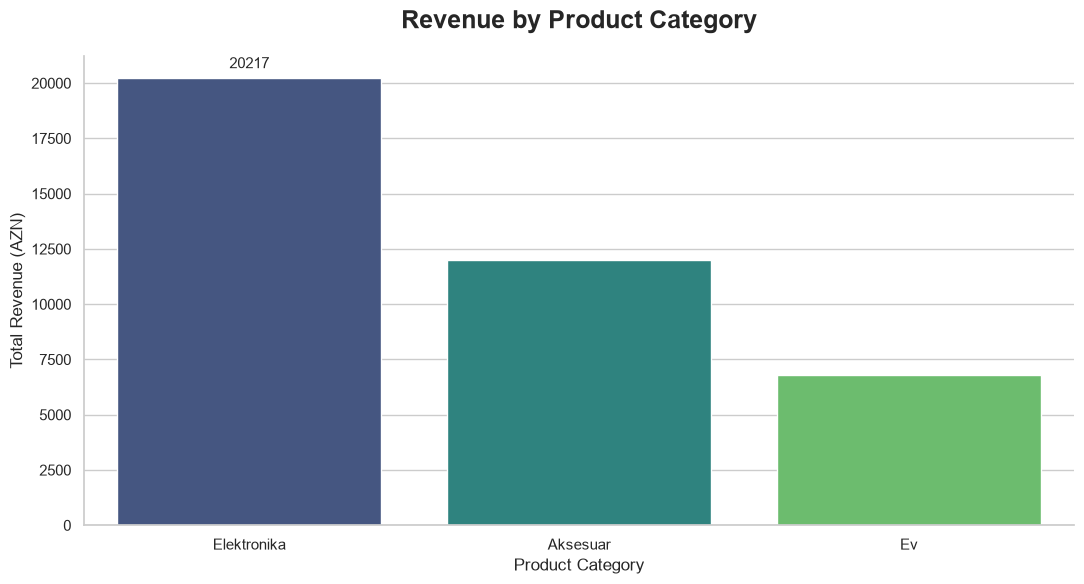

In [10]:
sns.set_theme(style="whitegrid", context="notebook")

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=category_analysis,
    x="category",
    y="total_revenue",
    hue="category",
    palette="viridis",
    legend=False
)

ax.set_title(
    "Revenue by Product Category",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Product Category", fontsize=12)
ax.set_ylabel("Total Revenue (AZN)", fontsize=12)

ax.bar_label(
    ax.containers[0],
    fmt="%.0f",
    padding=5,
    fontsize=11
)

sns.despine()
plt.tight_layout()
plt.show()

In [12]:
query = """
SELECT
    substr(o.order_date, 1, 7) AS month,

    SUM(
        oi.quantity * oi.unit_price * (1 - oi.discount)
    ) AS total_revenue,

    SUM(
        oi.quantity * oi.unit_price * (1 - oi.discount)
        - oi.quantity * oi.unit_cost
    ) AS total_profit

FROM orders o

JOIN order_items oi
    ON o.order_id = oi.order_id

GROUP BY substr(o.order_date, 1, 7)

ORDER BY month;
"""

monthly_analysis = pd.read_sql_query(query, conn)

display(monthly_analysis)

,month,total_revenue,total_profit
0,2025-01,2517.8,971.8
1,2025-02,3034.3,1139.3
2,2025-03,3303.8,1260.8
3,2025-04,2390.2,937.2
4,2025-05,2841.1,1096.1
5,2025-06,3711.4,1532.4
6,2025-07,3503.9,1383.9
7,2025-08,2960.2,1230.2
8,2025-09,3081.5,1131.5
9,2025-10,3812.6,1539.6


### 4.2 Monthly Revenue and Profit Trends

This chart illustrates monthly revenue and profit trends throughout 2025.

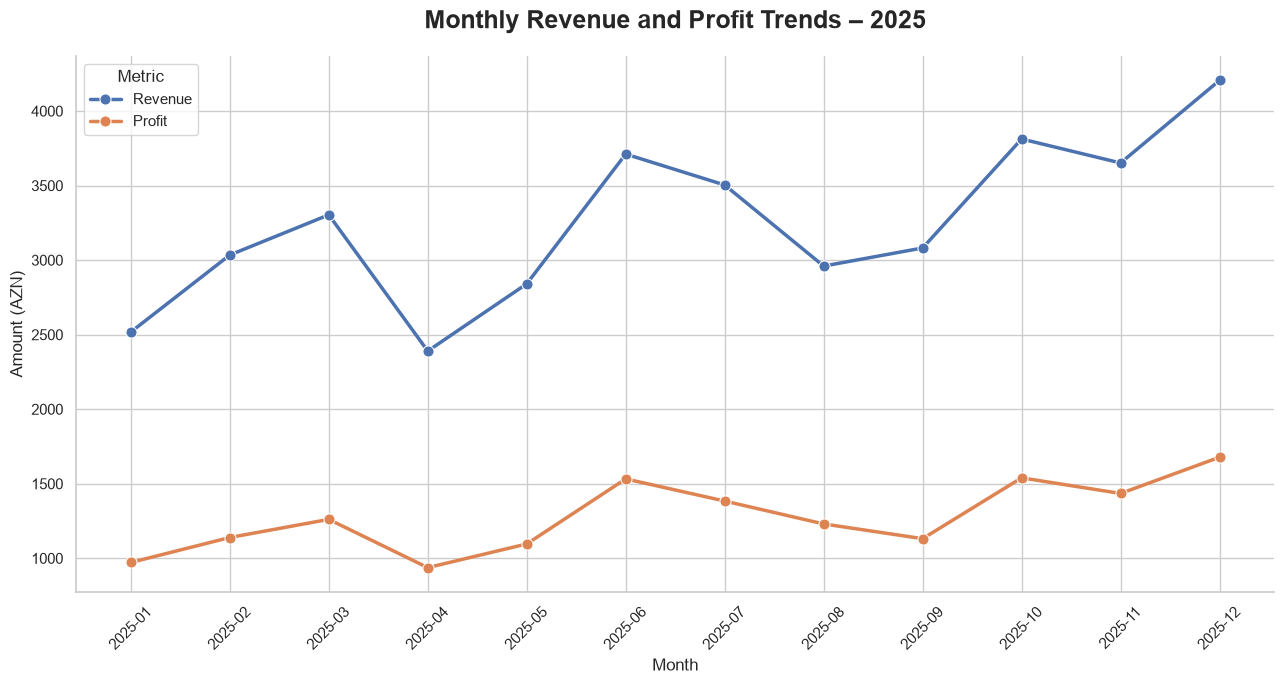

In [13]:
# Set visualization style
sns.set_theme(style="whitegrid", context="notebook")

# Create figure
plt.figure(figsize=(13, 7))

# Plot monthly revenue
sns.lineplot(
    data=monthly_analysis,
    x="month",
    y="total_revenue",
    marker="o",
    markersize=8,
    linewidth=2.5,
    label="Revenue"
)

# Plot monthly profit
sns.lineplot(
    data=monthly_analysis,
    x="month",
    y="total_profit",
    marker="o",
    markersize=8,
    linewidth=2.5,
    label="Profit"
)

# Add title and labels
plt.title(
    "Monthly Revenue and Profit Trends – 2025",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Amount (AZN)", fontsize=12)

# Format axes
plt.xticks(rotation=45)
plt.legend(title="Metric")

sns.despine()
plt.tight_layout()
plt.show()

### Business Insights – Monthly Trends

- December recorded the highest revenue (4,206 AZN) and profit (1,678 AZN).
- April recorded the lowest revenue (2,390.2 AZN) and profit (937.2 AZN).
- Revenue and profit increased significantly in June.
- October showed another strong increase in revenue and profit.
- Revenue and profit generally followed similar monthly trends.

**Key Finding:** December was the strongest month in 2025, while April was the weakest month.

### 4.3 Profit by Product Category

This chart compares total profit across different product categories.

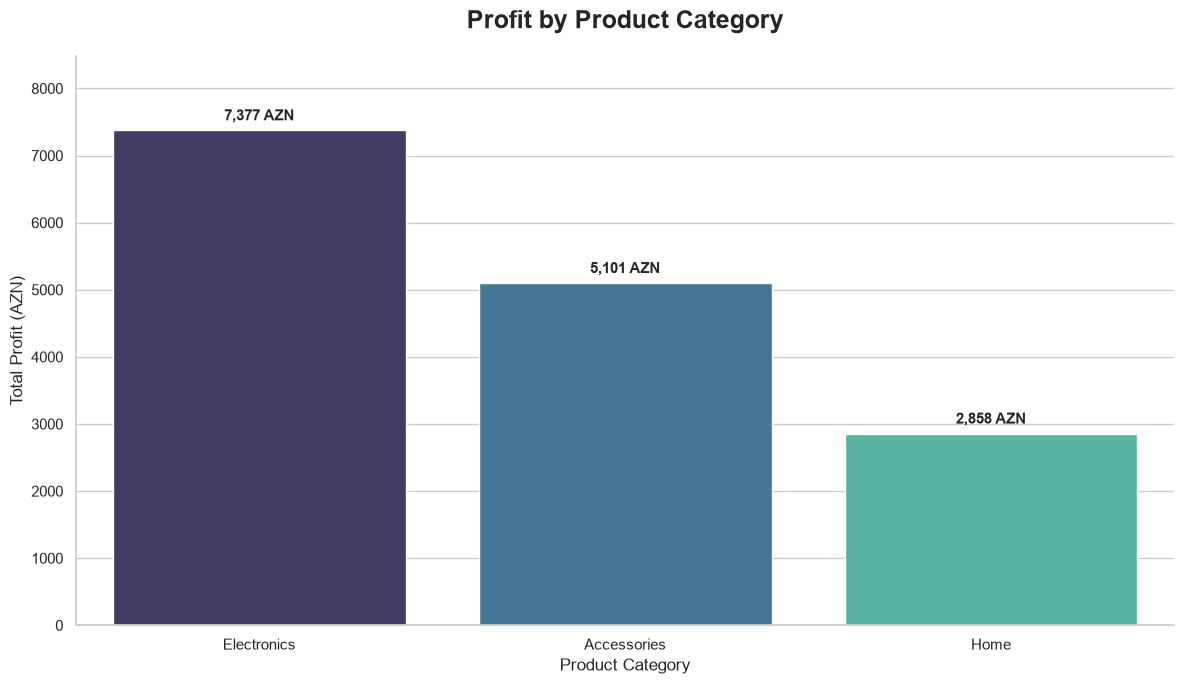

In [14]:
# Set visualization style
sns.set_theme(style="whitegrid", context="notebook")

# Create a copy of category analysis
profit_data = category_analysis.copy()

# Translate category names into English
category_labels = {
    "Elektronika": "Electronics",
    "Aksesuar": "Accessories",
    "Ev": "Home"
}

profit_data["category"] = profit_data["category"].map(category_labels)

# Create figure
plt.figure(figsize=(12, 7))

# Create bar chart
ax = sns.barplot(
    data=profit_data,
    x="category",
    y="total_profit",
    hue="category",
    palette="mako",
    legend=False
)

# Add title and labels
ax.set_title(
    "Profit by Product Category",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Product Category", fontsize=12)
ax.set_ylabel("Total Profit (AZN)", fontsize=12)

# Add values above bars
for bar in ax.patches:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 100,
        f"{height:,.0f} AZN",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Improve appearance
ax.set_ylim(0, profit_data["total_profit"].max() * 1.15)

sns.despine()
plt.tight_layout()
plt.show()

### Business Insights – Profit by Product Category

- Electronics generated the highest total profit (7,377 AZN).
- Accessories ranked second with 5,100.8 AZN in profit.
- Home generated the lowest total profit (2,857.7 AZN).
- Electronics is the main contributor to overall profit.

**Recommendation:** Maintain the strong profitability of Electronics and explore opportunities to improve the profit contribution of the Home category.

### 4.4 Profitability by Discount Rate

This chart illustrates how different discount rates affect profit per unit.

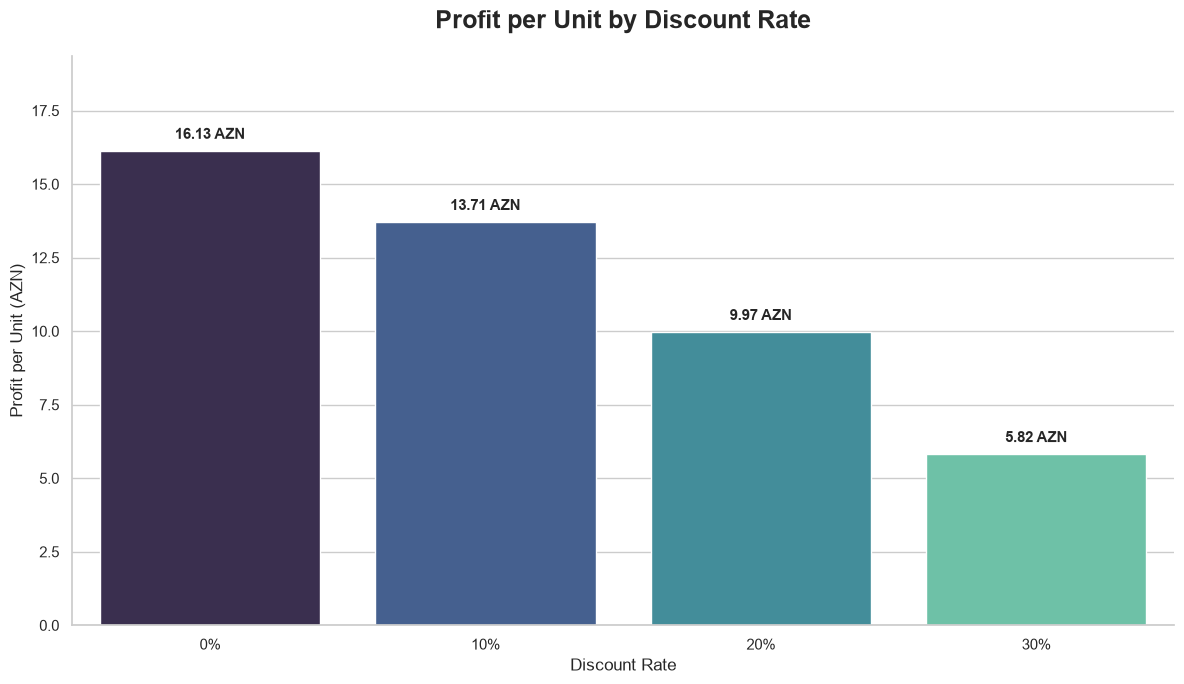

In [15]:
# Set visualization style
sns.set_theme(style="whitegrid", context="notebook")

# Create a copy of discount analysis
discount_data = discount_analysis.copy()

# Convert discount rates into percentages
discount_data["discount_label"] = (
    discount_data["discount"] * 100
).astype(int).astype(str) + "%"

# Create figure
plt.figure(figsize=(12, 7))

# Create bar chart
ax = sns.barplot(
    data=discount_data,
    x="discount_label",
    y="profit_per_unit",
    hue="discount_label",
    palette="mako",
    legend=False
)

# Add title
ax.set_title(
    "Profit per Unit by Discount Rate",
    fontsize=18,
    fontweight="bold",
    pad=20
)

# Add axis labels
ax.set_xlabel("Discount Rate", fontsize=12)
ax.set_ylabel("Profit per Unit (AZN)", fontsize=12)

# Add values above bars
for bar in ax.patches:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.3,
        f"{height:.2f} AZN",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Improve appearance
ax.set_ylim(0, discount_data["profit_per_unit"].max() * 1.2)

sns.despine()
plt.tight_layout()
plt.show()

### Business Insights – Discount Analysis

- Products without discounts generated the highest profit per unit (16.13 AZN).
- A 10% discount reduced profit per unit to 13.71 AZN.
- A 20% discount resulted in 9.97 AZN profit per unit.
- A 30% discount had the lowest profit per unit (5.82 AZN).
- Higher discount rates were associated with lower profit per unit.

**Recommendation:** Optimize discount strategies to balance sales volume and profitability.

# 5. Conclusion

## Key Findings

- Electronics generated the highest revenue (20,217 AZN) and total profit (7,377 AZN).
- Accessories achieved the highest profit margin (42.57%).
- December was the strongest month in terms of revenue and profit.
- April recorded the lowest monthly revenue and profit.
- Higher discount rates were associated with lower profit per unit.

## Business Recommendations

- Focus on high-performing product categories, especially Electronics.
- Explore opportunities to expand the Accessories category due to its high profit margin.
- Investigate the reasons behind weaker sales performance in April.
- Optimize discount strategies to maintain profitability.
- Monitor monthly revenue and profit trends to support business decisions.

## Final Conclusion

This project demonstrates how SQL and Python can be used to analyze sales data, identify business trends, evaluate product profitability, and generate actionable business recommendations.